### Práctica: Stock Market  

Objetivo:  
Desarrollar un agente de Deep Reinforcement Learning que sea capaz de tomar decisiones de compra, venta o mantenimiento de posiciones en el mercado de valores, basándose en datos históricos de precios de acciones. El objetivo del agente será maximizar la rentabilidad de la inversión a lo largo del tiempo.  

Datos:  
Utilizaremos la biblioteca yfinance de Python para obtener datos históricos de precios de acciones. Deberéis elegir una acción y analizar cómo el agente gestiona la diversificación del riesgo.  
https://es.ayuda.yahoo.com/kb/SLN2311.html?guccounter=1  
https://yahooquery.dpguthrie.com  

Parte 0 | Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf
import numpy as np
import random

import tensorflow as tf
from tqdm import tqdm_notebook, tqdm
from collections import deque
from keras.models import load_model
from tensorflow.math import sigmoid
from talib import RSI
from tensorflow.keras.regularizers import l2

Parte 1 | Preparación de Datos

Obtención de los datos, ya vienen ordenados por fecha, pero se añade un sort values por si acaso.

In [ ]:
df = pd.read_csv('../data/NVDA.csv').sort_values('date')
df

,symbol,date,open,high,low,close,volume,adjclose,dividends,splits
0,NVDA,1999-01-22,0.043750,0.048828,0.038802,0.041016,2714688000,0.037607,0.0,0.0
1,NVDA,1999-01-25,0.044271,0.045833,0.041016,0.045313,510480000,0.041547,0.0,0.0
2,NVDA,1999-01-26,0.045833,0.046745,0.041146,0.041797,343200000,0.038323,0.0,0.0
3,NVDA,1999-01-27,0.041927,0.042969,0.039583,0.041667,244368000,0.038204,0.0,0.0
4,NVDA,1999-01-28,0.041667,0.041927,0.041276,0.041536,227520000,0.038084,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
6743,NVDA,2025-11-11,195.160004,195.419998,191.300003,193.160004,176483300,193.160004,0.0,0.0
6744,NVDA,2025-11-12,195.720001,195.889999,191.130005,193.800003,154935300,193.800003,0.0,0.0
6745,NVDA,2025-11-13,191.050003,191.440002,183.850006,186.860001,207423100,186.860001,0.0,0.0
6746,NVDA,2025-11-14,182.860001,191.009995,180.580002,190.169998,186019700,190.169998,0.0,0.0


Se inicia la preparación de los datos. Se cambia el índice por la fecha para facilitar la visualización. (El tail de 2000 ejemplares es para realizar pruebas, para la entrega se utiliza el dataset completo).

In [3]:
df['date'] = pd.to_datetime(df['date'], errors='coerce') 
df.set_index('date', inplace=True)
df_reduced = df.tail(2000)
data = df

Separación de los conjuntos de entrenamiento y test. Se extrae aproximadamente el 3% del conjunto de datos completo para validación, y otro 3% para test. La separación se realiza respetando el marco temporal para que los datos tengan sentido. Además, se deja un gap de 15 días entre cada conjunto para evitar posibles data leakage.

In [4]:
data_samples = len(data) 
gap = 15
val_size = 180
test_size = 180 #aprox 6 meses
train_prices = data[:data_samples - val_size - test_size - gap * 2]
train_size = len(train_prices)
val_prices = data[train_size + gap : data_samples - test_size - gap]
test_prices = data[train_size + len(val_prices) + gap * 2:]

print(f"Train length: {train_size}")
print(f"Validation length: {len(val_prices)}")
print(f"Test length: {len(test_prices)}")

Train length: 6358
Validation length: 180
Test length: 180


Visualización de los precios en raw de todos los sets.

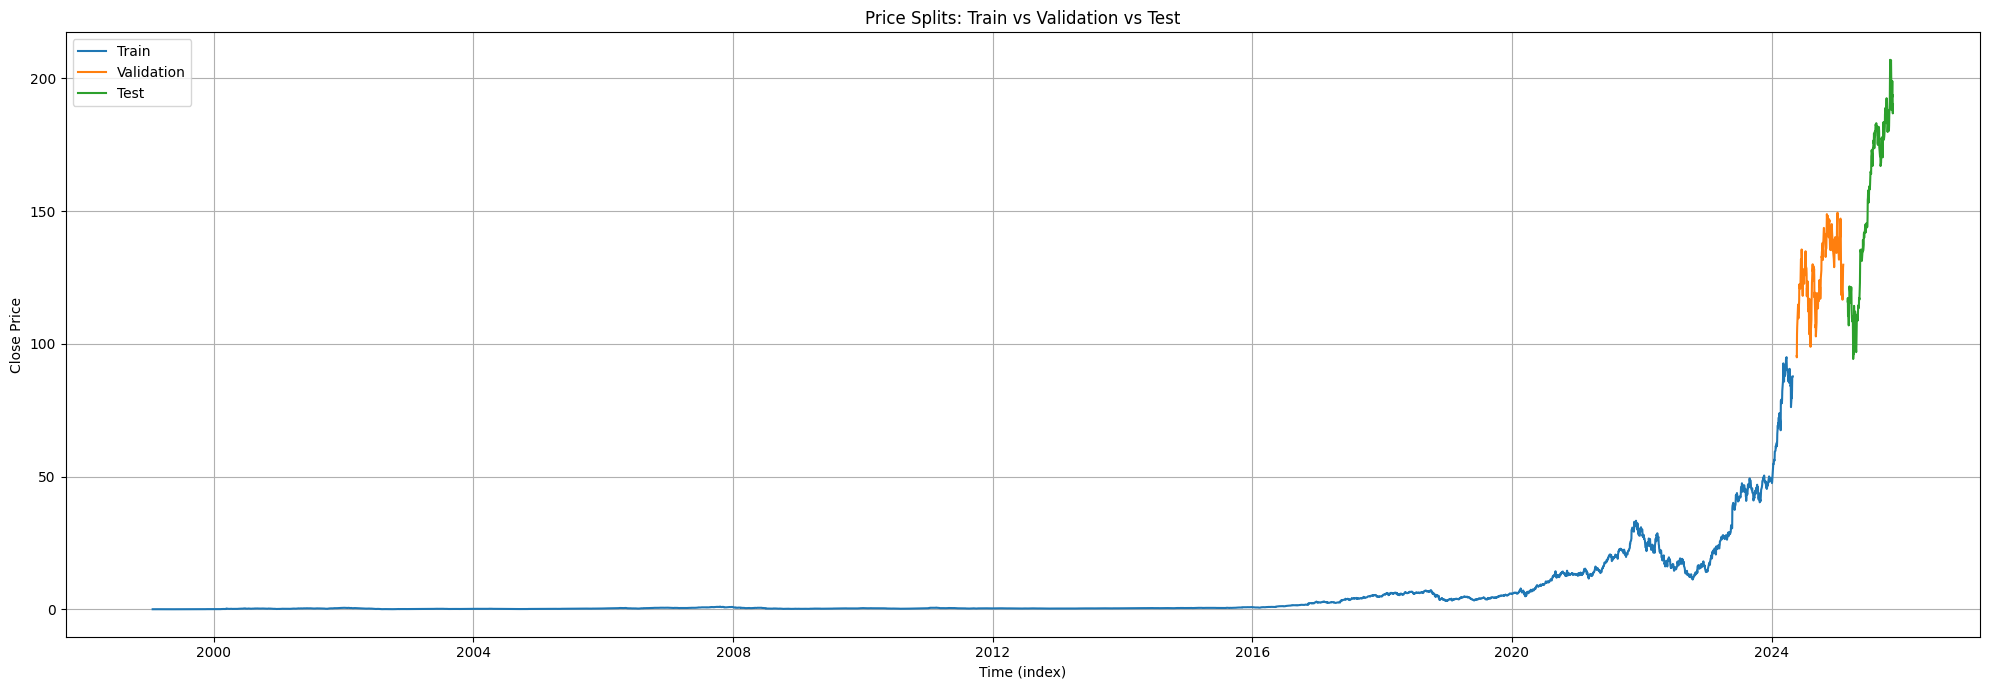

In [5]:
# display train and test raw prices
plt.figure(figsize=(20,7))

plt.plot(train_prices['close'], label="Train")
plt.plot(val_prices['close'], label="Validation")
plt.plot(test_prices['close'], label="Test")

# Labels
plt.title("Price Splits: Train vs Validation vs Test")
plt.xlabel("Time (index)")
plt.ylabel("Close Price")
plt.legend()
plt.grid(True)

plt.tight_layout()

Ingeniería de Características + Limpieza y Normalización:  

De los datos proporcionados por el dataset, se utilizará únicamente los precios de Close. Se extraen varias características informativas que ayudarán al DQN a aprender patrones. Se normaliza los precios de Close mediante Log returns ya que de esta manera los datos son estacionarios e invariantes a escala. Los demás datos no necesitan ser normalizados al estar ya en una escala aceptable.

In [6]:
# Obtener indicadores
def prepare_data(data):
    log_returns = np.log(data['close'] / data['close'].shift(1))
    data['log_returns'] = log_returns
    
    sma_10 = data['close'].rolling(window=10).mean()
    sma_50 = data['close'].rolling(window=50).mean()
    data['SMA_10'] = (data['close'] - sma_10) / sma_10
    data['SMA_50'] = (data['close'] - sma_50) / sma_50

    data['RSI'] = RSI(data['close'], timeperiod=14) / 100

    macd_line = data['close'].ewm(span=12, adjust=False).mean() - data['close'].ewm(span=26, adjust=False).mean()
    data['MACD'] = macd_line / data['close']

    #Limpieza de nulos
    data = data.dropna()

    return data

# Preparar para cada conjunto
train_features = prepare_data(train_prices.copy())
val_features = prepare_data(val_prices.copy())
test_features = prepare_data(test_prices.copy())

# Array de precios para pasarle al modelo para calcular ganancias y pérdidas en términos reales y no log return 
train_prices = train_prices['close'].values
val_prices = val_prices['close'].values
test_prices = test_prices['close'].values

Análisis técnico de los últimos 200 días del set de train.  
- Precio e indicadores de SMA (Moving Average): Los precios tienen una tendendia general altiva.  
- Volumen y RSI (Relative Strength Index): El volumen durante esta época fué bastante variante. El RSI > 0.7 a principios de 2024 indica un fuerte momentum (sobrecompra).  
- MACD (Moving Average Convergence Divergence): Indicador de momentum.  

En general, la gráfica muestra tendencia altiva con mucho momentum, por lo que es bastante posible que el agente tienda a una política de Buy-and-Hold.

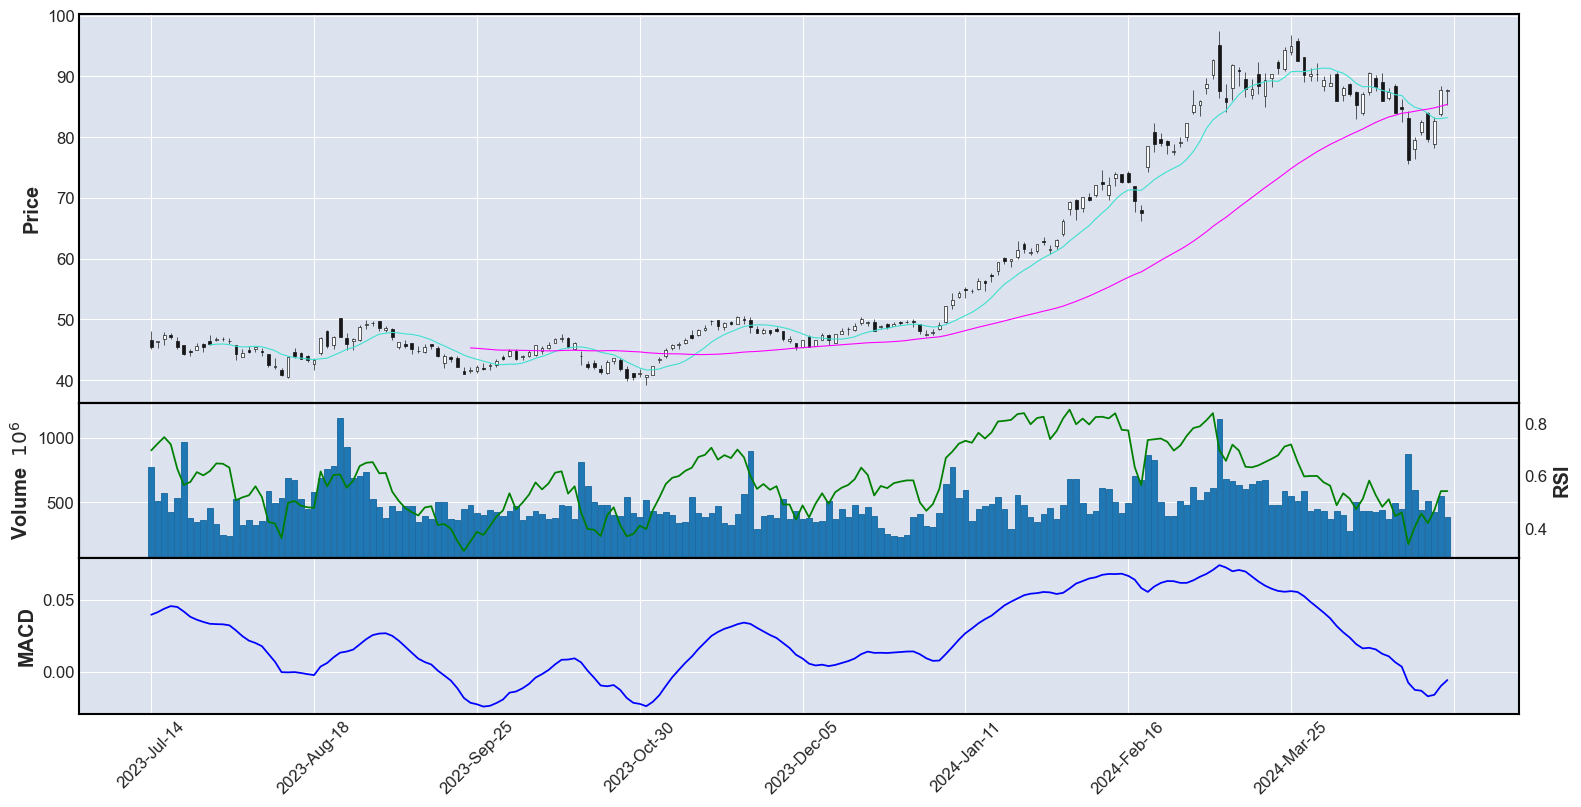

In [7]:
train_sample = train_features.tail(200)
mpf.plot(
    train_sample,
    type='candle',
    mav=(10,50), # Moving average de 10 y 50
    volume=True,
    addplot=[
        mpf.make_addplot(train_sample['RSI'], panel=1, color='green', ylabel='RSI'),
        mpf.make_addplot(train_sample['MACD'], panel=2, color='blue', ylabel='MACD')
    ],
    figsize=(20,10),
)

Correlación entre las características extraídas y comparación entre los distintos conjuntos.  

Entre las distintas características, destaca sobretodo una fuerte correlación entre SMA_50 tanto con MACD como con RSI, tiene sentido ya que todas tienden a capturar una señal lenta. Al estar tan altamente correlacionados, se decide eliminar SMA_50 de los datos para evitar multicolinealidad.  

La estructura de correlación se mantiene consistente a través de los distintos conjuntos, indicando que las relaciones aprendidas durante train serán válidas para una correcta validación en test.

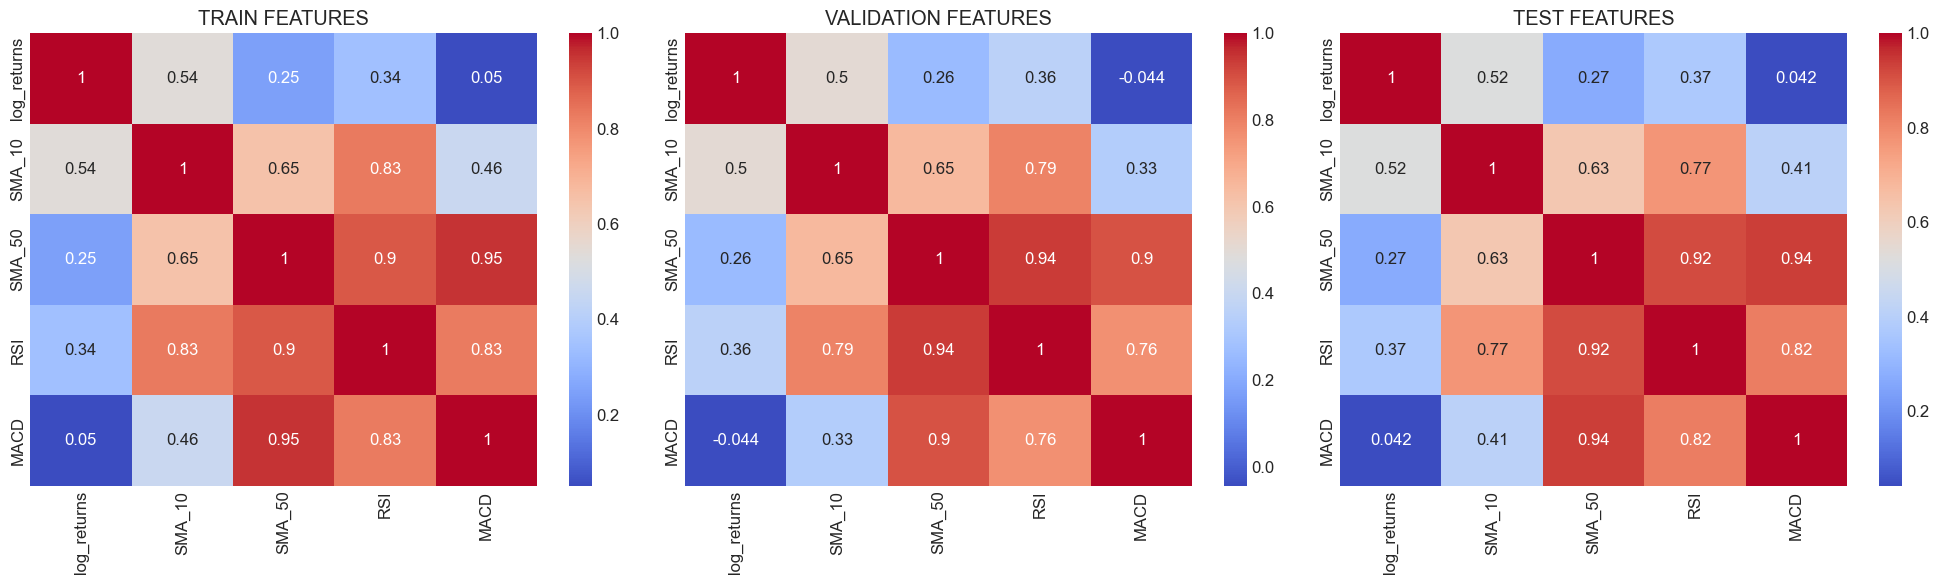

In [8]:
def matrix_plot(sets):
    fig, axs = plt.subplots(1, 3, figsize=(20,6))
    for i, f in enumerate(sets):
        sns.heatmap(f[0][['log_returns','SMA_10','SMA_50','RSI','MACD']].corr(), annot=True, cmap='coolwarm', ax=axs[i])
        axs[i].set_title(f[1])
    plt.tight_layout()
    plt.show()

matrix_plot([[train_sample, "TRAIN FEATURES"], [val_features, "VALIDATION FEATURES"], [test_features, "TEST FEATURES"]])

Análisis de la distribución de características.  

- Log returns mantiene una distribución normal con mediana centrada en 0. El rango se mantiene en aproximadamente -0.05 y 0.05 y pocos outliers tanto en train como en validación. Test tiene más outliers.  
- RSI tiene una distribución plana en todos los conjuntos, sin mostrar momentos de oversold significativos (<0.3), lo que indica que el mercado constantemente tiende a una direccionalidad hacia arriba.  
- MACD tiende a mostrar varios picos indicando que el trend de momentum no es uniforme. Train y test tienen una concentración positiva superior, indicando que el momentum a corto plazo fué más fuerte que a largo plazo.  

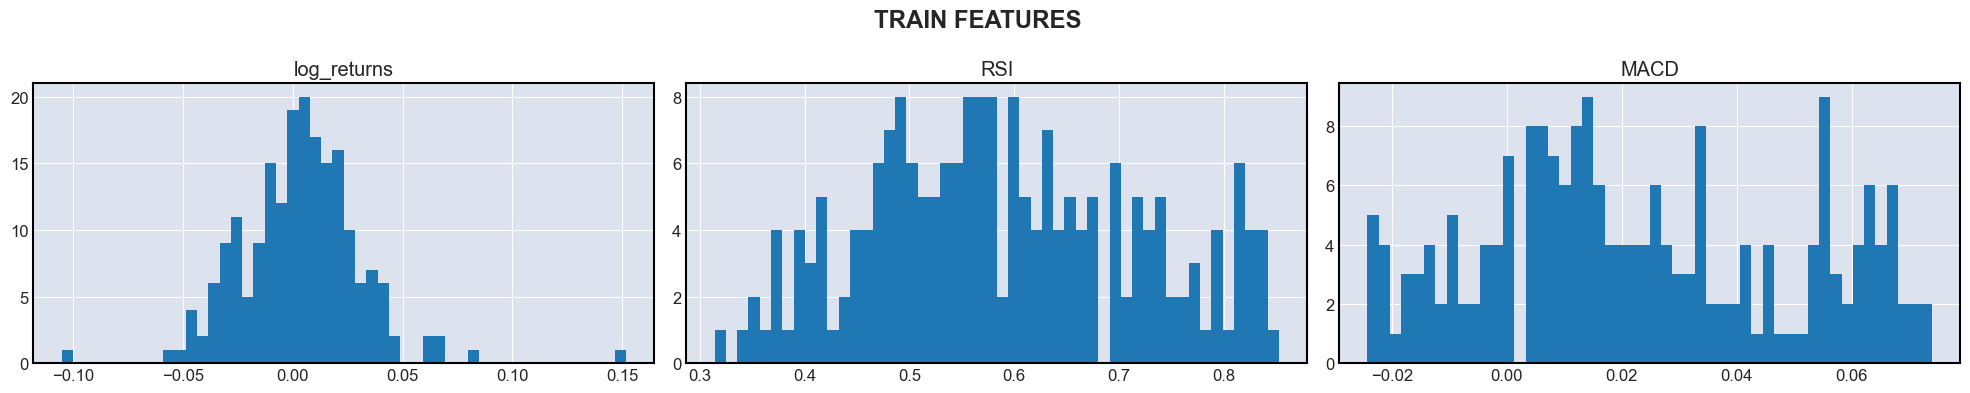

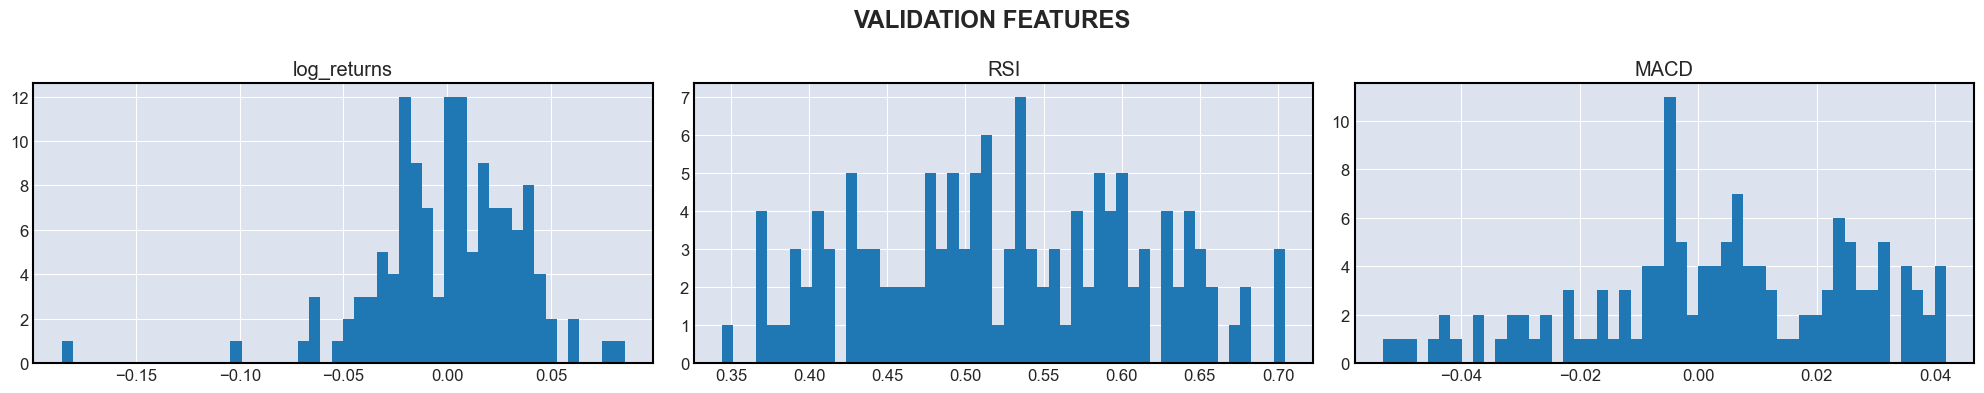

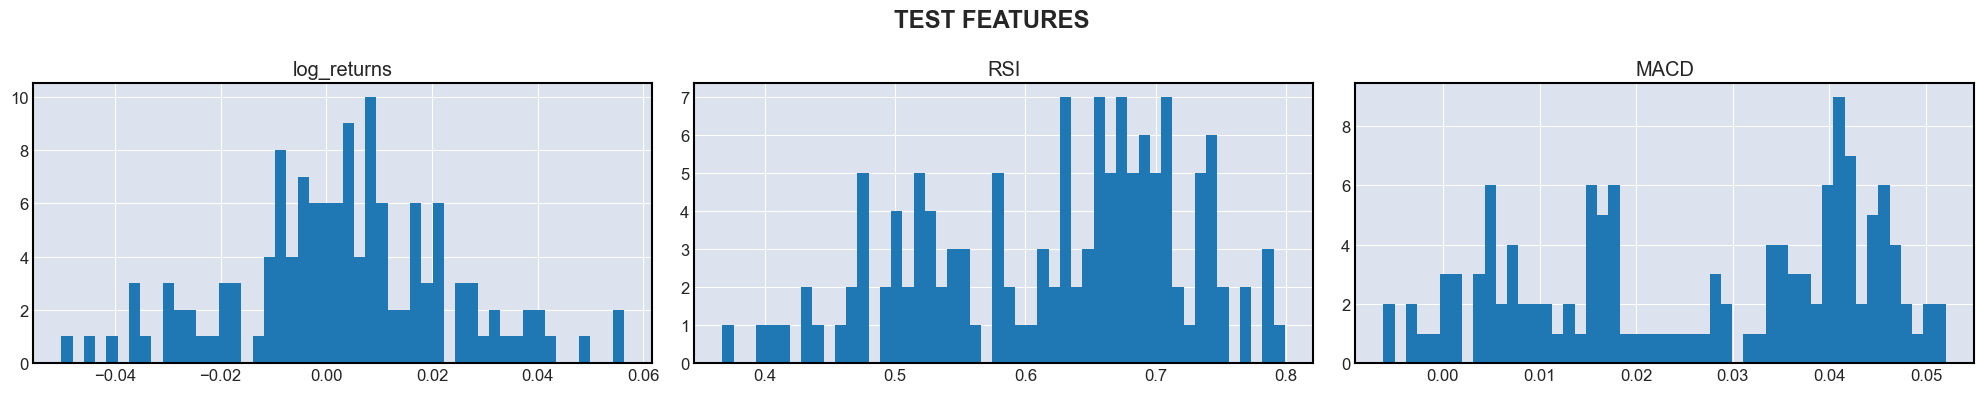

In [9]:
def grid_plot(df, title=""):
    features = ['log_returns', 'RSI', 'MACD']
    
    fig, axs = plt.subplots(1, 3, figsize=(20,4))
    for i, f in enumerate(features):
        df[[f]].hist(bins=50, figsize=(20,6), ax=axs[i])
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

grid_plot(train_sample, "TRAIN FEATURES")
grid_plot(val_features, "VALIDATION FEATURES")
grid_plot(test_features, "TEST FEATURES")

Eliminación de características.

In [10]:
train_features.drop(columns=['symbol', 'open', 'high', 'low', 'close', 'volume', 'adjclose', 'dividends', 'splits', 'SMA_50'], inplace=True)
val_features.drop(columns=['symbol', 'open', 'high', 'low', 'close', 'volume', 'adjclose', 'dividends', 'splits', 'SMA_50'], inplace=True)
test_features.drop(columns=['symbol', 'open', 'high', 'low', 'close', 'volume', 'adjclose', 'dividends', 'splits', 'SMA_50'], inplace=True)

Parte 2 | Implementación del modelo (DQN)

Definición de variables.

In [11]:
# Se escoge un rango grande de episodios, para que el early stopping tenga margen de ejecución. 
episodes = 500 
batch_size = 128
start_capital = 10000

Definición de la clase Trader.

In [ ]:
class AI_Trader():
    def __init__(self, state_size, action_space=3, wallet=start_capital, model_name="AITrader"):
        #Estados: Mantenerse (0), Comprar (1) , Vender (2)

        self.state_size = state_size
        self.action_space = action_space
        self.wallet = wallet
        # Al usar el dataset entero, se generan más de 6000 memorias nuevas por episodio. El agente empezaría a perder memoria tras unos 8 episodios.
        self.memory = deque(maxlen=50000)
        self.inventory = [] # Guarda las acciones que tiene el agente en hold.
        self.transactions = [] # Registro de tipo de transacción para mostrar en gráfica [episodio, acción (0,1,2), precio]
        self.trades = [] # Registro de retorno de ganancias o pérdidas en cada transacción -> se usará para las métricas.
        self.model_name = model_name

        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_final = 0.01
        self.epsilon_decay = 0.95

        # Se utilizarán 2 modelos (iniciados iguales). Uno para las Q actuales, y otra para las Q-target
        self.model = self.model_builder()
        self.target_model = self.model_builder()
        self.update_target_model() # Inicializar con los mismos pesos
        self.target_update_counter = 0 # Contador de iteraciones hasta que se decide actualizar los pesos del modelo target

    # Arquitectura del modelo
    def model_builder(self):
        model = tf.keras.models.Sequential()
        model.add(tf.keras.layers.Dense(units=64, activation='relu', input_dim=self.state_size))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(units=64, activation='relu', kernel_regularizer=l2(0.001)))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(units=32, activation='relu'))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(units=self.action_space, activation='linear'))

        model.compile(
            # La función de pérdida huber va bien para datos financieros, ya que es muy robusto a rémenes de mercado
            # Huber combina MSE y MAE con el parámetro delta:
            # Si los errores son menores a delta, se tratan como MSE normal, pero si son mayores, se tratan como ruido (MAE)
            loss='huber', 
            # Se utiliza AdamW como función de optimización.
            # A diferencia del Adam normal, éste aplica el weight decay directamente sobre los pesos, en vez de por los gradientes. 
            # Esto ayuda a una mejor convergencia sobretodo en entornos ruidosos como los financieros.
            # (Básicamente su regularización de pesos es más robusta a datos ruidosos por lo que es más efectiva en cuanto al overfitting)
            optimizer=tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.01, clipnorm=1.0), # clipnorm=gradient clipping
            # Habilita la compilación XLA (Accelerated Linear Algebra) -> compila la función de entrenamiento por lo que lo hace mucho más rápido.
            # Se basa en fusionar operaciones y ejecutarlas todas a la vez (ganando en uso de kernel y memoria)
            jit_compile=True,
            )
        
        return model
    
    # Función para actualizar los pesos del modelo target con los pesos del modelo principal.
    def update_target_model(self):
        self.target_model.set_weights(self.model.get_weights())


    # Función para decidir la acción a tomar por agente
    def trade(self, state):
        # Explorar Vs Explotar:  
        # Genero una decisión aleatoria (como al principio epsilon=1 siempre será true, pero después irá disminuyendo)
        if random.random() <= self.epsilon: 
          return random.randrange(self.action_space) 

        # Usar direct call en vez de model.predict para minimizar sobrecarga
        # Usar training false para desactivar dropout para que la predicción sea determinista y se comporte como en la evaluación
        actions = self.model(state, training=False)
        return np.argmax(actions[0]) # Devolver la acción con más probabilidad


    # Función para llamar al .fit (Batch size=128)
    def batch_train(self, batch_size):
        # No se entrena sin suficiente memoria
        if len(self.memory) < batch_size:
            return None

        # Se escoge un conjunto aleatorio del tamaño de batch size de toda la memoria disponible
        batch = random.sample(self.memory, batch_size)

        # Matriz de estados (s) actuales y estados futuros (s')
        states = np.array([sample[0][0] for sample in batch])
        next_states = np.array([sample[3][0] for sample in batch])

        # Predecir las Q para los estados (s) actuales y futuros (s')
        current_qs = self.model(states, training=False).numpy() # Predichas con el modelo principal
        next_qs = self.target_model(next_states, training=False).numpy() # Predichas con el modelo target

        # Arrays para rellenar con los datos a pasarle al modelo para que haga el .fit
        X = []
        y = []

        # Iterar sobre cada elemento del batch seleccionado aleatoriamente de la memoria
        for index, (state, action, reward, next_state, done) in enumerate(batch): # (S, A, R, S') (done indica que es el último del batch)
            if not done:
                reward = reward + self.gamma * np.max(next_qs[index]) # Q-target = R(s, a) + factor de descuento * max(Q(s', a'))

            target = current_qs[index].copy()
            target[action] = reward
            
            X.append(state[0])
            y.append(target)

        # Entrenamiento con el estado actual y el objetivo predicho
        self.model.fit(np.array(X), np.array(y), batch_size=batch_size, epochs=1, verbose=0)

        # Sumar 1 al contador para actualizar los pesos del modelo target
        self.target_update_counter += 1
        # Actualizar tras 500 iteraciones 
        # (6358 entradas, y se entrena cada 5 iteraciones, son 1271 entrenamientos por episodio -> unas 2 actualizaciones de modelo target por episodio)
        if self.target_update_counter % 500 == 0:
            self.update_target_model()
            self.target_update_counter = 0 # Resetear contador

    
    # Función para reducir épsilon
    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_final, self.epsilon * self.epsilon_decay)

    # FUNCIONES AUXILIARES
    # Función para calcular Kelly Criterion
    # Kelly es una fórmula usada en teoría de la probabilidad e inversión para determinar el tamaño óptimo de apuestas o inversiones para maximizar el retorno a largo tiempo.
    def calculate_kelly_size(self):
        trades = self.trades
        # Si no hay mucho historial de trades, se inicia conservativo (si capital disponible 10000, la fracción a invertir sería 1000)
        if len(trades) < 20:
            return 0.1
        
        # Obtener arrays para separar las ganancias y pérdidas de las 50 últimas transacciones
        recent_trades = trades[-50:]
        wins = [t for t in recent_trades if t > 0]
        losses = [t for t in recent_trades if t <= 0]
        
        # Si no hay métricas para ambas posibilidades no se puede calcular, por lo que devuelve lo mismo que si no hubiera suficiente información
        if not wins or not losses:
            return 0.1
        
        # Calcular el ratio de ganancias y pérdidas
        win_rate = len(wins) / len(recent_trades)
        avg_win = np.mean(wins)
        avg_loss = abs(np.mean(losses))
        
        
        # Fórmula: kelly = (probabilidad de ganar * b - probabilidad de perder) / b
        # (b = ratio de ganancias vs pérdidas)
        b = avg_win / avg_loss if avg_loss > 0 else 1
        kelly = (win_rate * b - (1 - win_rate)) / b
        
        # Si kelly es negativo, comprará una fracción de 0.01
        # Si es positivo, mínimo comprará una fracción de 0.5, o la cantidad que establezca la fórmula
        kelly = max(0.01, min(kelly, 0.50))
        
        return kelly

    # Función para calcular la recompensa
    def calculate_reward(self, action, current_price, prev_price):
        # Variables para indicar recompensa obtenida y validez de la acción escogida
        reward = 0
        valid = True

        # HOLD
        if action == 0:
            # Castigo por no actuar cuando inventario vacío (no quedarse quieto)
            if len(self.inventory) == 0:
                reward = -0.01 
            else:
                # Calcular el log return de los precios actuales
                log_ret = np.log(current_price / prev_price)
                # Calcular valor de inventario
                total_shares = sum([qty for _, qty in self.inventory])
                total_cost = sum([price * qty for price, qty in self.inventory])
                
                if total_cost > 0:
                    # Penalizar o recompensar en base a la posición actual en relación con el precio de mercado actual
                    current_value = total_shares * current_price
                    unrealized_pnl = (current_value - total_cost) / total_cost

                    if unrealized_pnl > 0:
                        reward = log_ret * 1.2
                    else:
                        reward = log_ret * 2.0  # Si el estado actual de mercado está decayendo, se penaliza más por mantener la posición
                    
                    # Establecer límite de recompensa
                    reward = np.clip(reward, -0.05, 0.05)
            # Incentivo para tomar acción
            reward -= 0.0001

        # BUY
        elif action == 1:
            kelly_fraction = self.calculate_kelly_size() # Fracción de kelly óptimo para invertir
            capital_to_use = self.wallet * kelly_fraction # Capital total para gastar
            shares_to_buy = int(capital_to_use / current_price) # Cantidad de acciones a comprar
            cost = shares_to_buy * current_price # Coste total de compra

            # Realizar la compra
            if shares_to_buy > 0 and self.wallet >= cost:
                self.wallet -= cost
                self.inventory.append((current_price, shares_to_buy))
                reward = -0.0001 # Coste de transacción (para que no se dedique únicamente a comprar)
            # Csatigo por compra fallida (intento de compra cuando kelly es negativo o no hay sificiente capital)
            else: 
                reward = -0.01
                valid = False
            # Castigo por mantener demasiado inventario sin liquidar
            if len(self.inventory) > 10:
                reward = -0.01

        # SELL
        else:
            # Liquidar inventario según FIFO
            if len(self.inventory) > 0:
                (buy_price, qty) = self.inventory.pop(0)
                total_cost = buy_price * qty
                revenue = qty * current_price 
                ret = (revenue - total_cost) / total_cost if total_cost != 0 else 0
                
                # Realizar la venta
                self.trades.append(ret)
                self.wallet += revenue
                reward = np.clip(ret, -0.5, 0.5) # Limitar la recompensa por transacciones muy ruidosas
                
                # Recompensa adicional por ventas ganadoras
                if ret > 0.05:
                    reward += 0.05
            # Castigo por intentar vender cuando no hay nada que vender
            else:
                reward = -0.01
                valid = False

        # Recompensa indiferente a la acción escogida, según el sharpe de las útimas transacciones
        if len(self.trades) > 20:
            recent = self.trades[-50:]
            mean_return = np.mean(recent)
            std_return = np.std(recent)
            if std_return > 0:
                sharpe = mean_return / std_return
                reward += np.clip(sharpe * 0.005, -0.02, 0.02) # Limitado

        return reward, valid
    
    # Función para obtener el valor del portfolio (efectivo + valor de acciones actual) - capital inicial
    def get_portfolio_value(self, current_price):
        total_shares = sum([qty for _, qty in self.inventory])
        return self.wallet + (total_shares * current_price) - start_capital
    
    # Borrar inventario y datos de transacciones y resetear billetera para nuevo episodio
    def reset_for_episode(self):
        self.inventory = []
        self.trades = []
        self.wallet = start_capital

    # Función para obtener métricas
    def get_metrics(self, episode, last_price):
        # Liquidar inventario restante
        if len(self.inventory) > 0:
            for (buy_price, qty) in self.inventory:
                profit = last_price - buy_price
                ret = profit / buy_price
                self.trades.append(ret)
                self.wallet += last_price * qty

        # Cálculo de métricas
        trades = np.array(self.trades, dtype=float)
        if len(trades) > 0:
            avg_trade = np.mean(trades)
            wins = trades[trades > 0]
            losses = trades[trades <= 0]
        else:
            avg_trade = 0
            wins = []
            losses = []

        std_trades = np.std(trades, ddof=0) if len(trades) > 1 else 0

        return {
            'episode': episode,
            'total_profit': self.get_portfolio_value(last_price),
            'num_trades': len(trades),
            'win_rate': len(wins) / len(trades) if len(trades) > 0 else 0,
            'avg_profit_per_trade': avg_trade,
            'epsilon': self.epsilon,
            'avg_loss': np.mean(losses) if len(losses) > 0 else 0,
            'sharpe': avg_trade / std_trades if std_trades != 0 else 0
        }

In [13]:
# State creator (función auxiliar)
def state_creator(data, timestep, inventory, current_price, wallet):
    # Por si el tiempo (t) cae fuera de los límites
    if timestep >= len(data):
        timestep = len(data) - 1
    if timestep < 0:
        timestep = 0

    # Obtener las características de t día
    features = data.iloc[timestep].values

    # Obtener información sobre la posición actual
    total_shares = sum([qty for _, qty in inventory]) if inventory else 0
    position_value = total_shares * current_price
    portfolio_value = wallet + position_value
    
    # Obtener el valor de las acciones del inventario actual entre el portfolio total (posición + billetera)
    if inventory:
        position_size = position_value / portfolio_value if portfolio_value > 0 else 0
    
    # Obtener el beneficio no realizado = Posición actual - el coste (es decir las ganancias o pérdidas del inventario)
        total_cost = sum([price * qty for price, qty in inventory])
        unrealized_pnl = (position_value - total_cost) / total_cost if total_cost > 0 else 0
    else:
        position_size = 0
        unrealized_pnl = 0
    
    # Juntar todas las características y métricas y preparalo para el formato de salida
    state = np.append(features, [position_size, unrealized_pnl])
    return state.reshape(1, -1)

num_features = len(train_features.columns) + 2 # +1 por la posición en inventario y +1 por unrealized profit

Parte 3 | Entrenamiento

In [ ]:
# Evaluación del modelo (Función auxiliar)
def evaluate_model(episode, trader, test_features, test_prices):
    # Guardar datos del modelo original
    original_epsilon = trader.epsilon
    original_inventory = trader.inventory
    original_wallet = trader.wallet
    trader.epsilon = 0.0 # Epsilon se deja a 0 para que las decisiones del agente no sean random
    trader.reset_for_episode()

    eval_transactions = [] # Array vacío para ir guardando las transacciones para después mostrarlas en gráfica

    # Estado inicial
    state = state_creator(test_features, 0, trader.inventory, test_prices[0], trader.wallet)

    # Bucle por todos los días
    for t in tqdm(range(test_size - 1), leave=False):
        current_price = test_prices[t]
        action = trader.trade(state) # Obtener la predicción
        
        # Lógica de compra o venta está dentro de calculate reward
        _, valid = trader.calculate_reward(action, current_price, test_prices[t-1]) 
        # Si la acción no es válida se sobreescribe como hold
        if valid == False:
            action = 0
            
        # Registrar la transacción y creación del siguiente estado
        eval_transactions.append((t, action, test_prices[t]))
        state = state_creator(test_features, t+1, trader.inventory, test_prices[t+1], trader.wallet)

    # Obtención de las métricas 
    row = trader.get_metrics(episode, test_prices[-1])

    # Reescribir trader con los datos originales
    trader.epsilon = original_epsilon
    trader.inventory = original_inventory
    trader.wallet = original_wallet

    return (row, eval_transactions)

In [15]:
trader = AI_Trader(state_size=num_features)

# Dataframe para guardar las métricas
metrics = pd.DataFrame(columns=['episode', 'total_profit', 'num_trades', 'win_rate', 'avg_profit_per_trade', 'epsilon', 'avg_loss', 'sharpe'])
val_metrics = pd.DataFrame(columns=['episode', 'total_profit', 'num_trades', 'win_rate', 'avg_profit_per_trade', 'epsilon', 'avg_loss', 'sharpe'])

# Variables para trackear el mejor modelo
best_val_metrics = -np.inf 
best_episode = 0
patience = 25
no_improvement_count = 0

# Main (entrenamiento)
for episode in range(1, episodes + 1):
    # Resetear inventario, trades y cartera para cada episodio 
    trader.reset_for_episode()

    # Creación de state primero
    state = state_creator(train_features, 0, trader.inventory, train_prices[0], trader.wallet)
    # Array para guardar las transacciones de este ciclo
    episode_transactions = []
    
    # Para cada episodio paso por todo el dataset (t-> día, tqdm -> cola)
    for t in tqdm(range(train_size - 1), leave=False):
        current_price = train_prices[t] # Precio del día
        
        # Predecir la acción y creación del siguiente estado
        action = trader.trade(state)
        next_state = state_creator(train_features, t+1, trader.inventory, train_prices[t+1], trader.wallet)

        # Recompensa obtenida y lógica de compra o venta
        reward, valid = trader.calculate_reward(action, current_price, train_prices[t-1])
        if valid == False: # Si no es válido holdea
            action = 0
        # Variable para determinar si es último de la cola
        done = t == train_size -1
        
        # Registrar la transacción, la memoria
        episode_transactions.append((t, action, current_price))
        trader.memory.append((state, action, reward, next_state, done))
        state = next_state

        # Se entrena únicamente cada 5 pasos
        if t % 5 == 0 and len(trader.memory) > batch_size:
            trader.batch_train(batch_size)
    
    # Calcular métricas
    metrics.loc[len(metrics)] = trader.get_metrics(episode, train_prices[-1])
    # Registrar la lista completa de transacciones de este ciclo en una lista de transacciones de todas las épocas
    trader.transactions.append(episode_transactions)
    
    print(metrics.iloc[-1].to_dict())

    # Evaluar en datos de validación
    val_results, _ = evaluate_model(episode, trader, val_features, val_prices)
    current_metric = val_results['sharpe']
    # Regristrar las métricas obtenidas en el Dataframe
    val_metrics.loc[len(val_metrics)] = val_results
    # Si el sharpe obtenido es el mejor hasta ahora, se guarda
    if current_metric > best_val_metrics:
        best_val_metrics = current_metric
        best_episode = episode
        best_weights = trader.model.get_weights()
        no_improvement_count = 0
        
        print(f"New best model - {val_results}")
        trader.model.save(f"ai_trader_{episode}.keras")
    else:
        no_improvement_count += 1

    # Si se llega al límite de paciencia del early stopping, termina
    if no_improvement_count >= patience:
        print(f"Early stopping at episode: {episode}")
        break

    # Guardado por si acaso cada 10 episodios
    if episode % 10 == 0:
        trader.model.save("ai_trader_{}.keras".format(episode))
 
    # Bajar epsilon
    trader.decay_epsilon()

C:\Users\chena\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'episode': 1.0, 'total_profit': 3358364.6403034367, 'num_trades': 2116.0, 'win_rate': 0.6318525519848771, 'avg_profit_per_trade': 0.11863837430145102, 'epsilon': 1.0, 'avg_loss': -0.17269732954119316, 'sharpe': 0.3540317250424185}


New best model - {'episode': 1, 'total_profit': 10729.919921875, 'num_trades': 92, 'win_rate': 0.782608695652174, 'avg_profit_per_trade': 0.06342328286585841, 'epsilon': 0.0, 'avg_loss': -0.023542011884414245, 'sharpe': 0.7880753113704817}


{'episode': 2.0, 'total_profit': 13918376.863467589, 'num_trades': 2154.0, 'win_rate': 0.692200557103064, 'avg_profit_per_trade': 0.2685308985727592, 'epsilon': 0.95, 'avg_loss': -0.21093348938210987, 'sharpe': 0.5235547081172496}


{'episode': 3.0, 'total_profit': 1594709.9976218157, 'num_trades': 2139.0, 'win_rate': 0.6624590930341281, 'avg_profit_per_trade': 0.09923470868664488, 'epsilon': 0.9025, 'avg_loss': -0.16398259765097078, 'sharpe': 0.3526742898383395}


New best model - {'episode': 3, 'total_profit': 8061.914909362793, 'num_trades': 90, 'win_rate': 0.7888888888888889, 'avg_profit_per_trade': 0.04376403482465783, 'epsilon': 0.0, 'avg_loss': -0.028936701861319445, 'sharpe': 0.7993909152354599}


... (29 outputs left out)

{'episode': 31.0, 'total_profit': -166.04792740567427, 'num_trades': 473.0, 'win_rate': 0.48625792811839325, 'avg_profit_per_trade': 0.001293057552015405, 'epsilon': 0.2146387639429372, 'avg_loss': -0.027482159964602276, 'sharpe': 0.02927249549201903}


{'episode': 32.0, 'total_profit': 4.614811882374852, 'num_trades': 444.0, 'win_rate': 0.48873873873873874, 'avg_profit_per_trade': 0.00037282642739566393, 'epsilon': 0.20390682574579033, 'avg_loss': -0.0279910889006693, 'sharpe': 0.008089258782540677}


{'episode': 33.0, 'total_profit': 1988.9718206263897, 'num_trades': 385.0, 'win_rate': 0.5194805194805194, 'avg_profit_per_trade': 0.0030547557346120276, 'epsilon': 0.1937114844585008, 'avg_loss': -0.024126420056353917, 'sharpe': 0.07537250927993203}


Early stopping at episode: 33


Visualización de las métricas de entrenamiento y validación

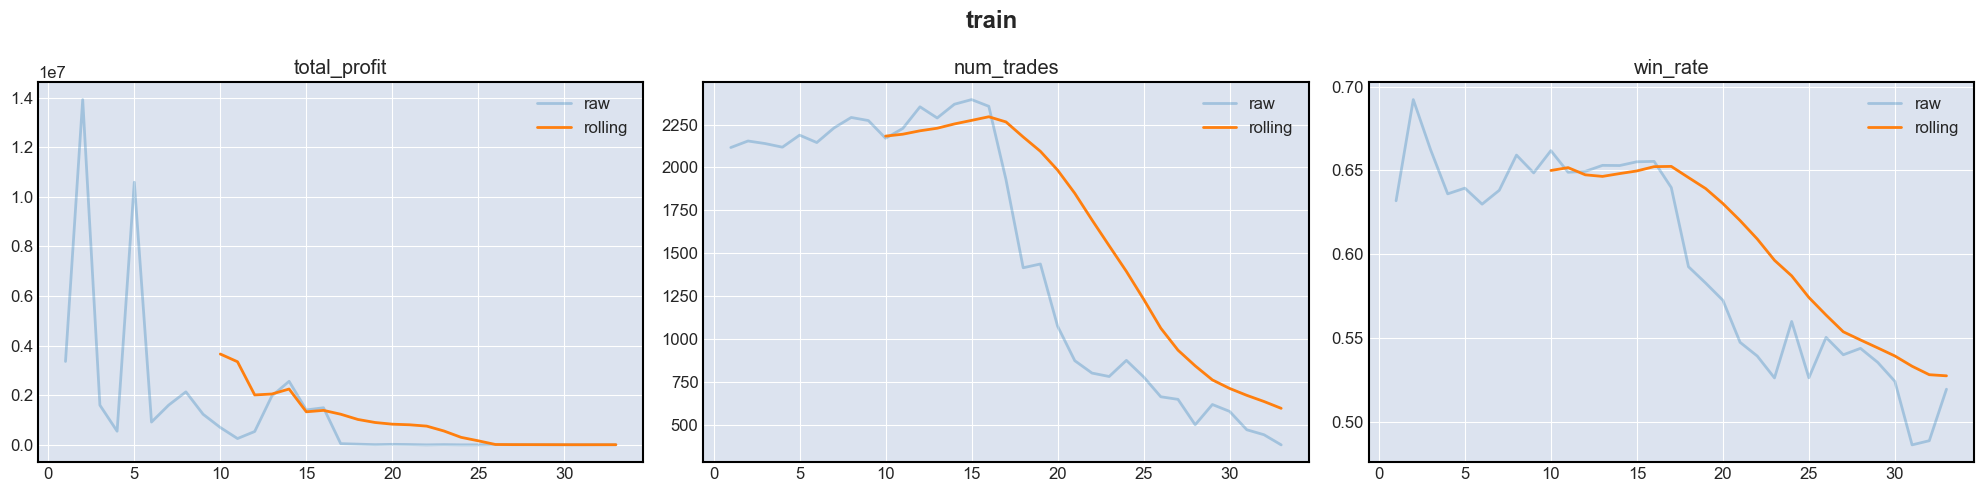

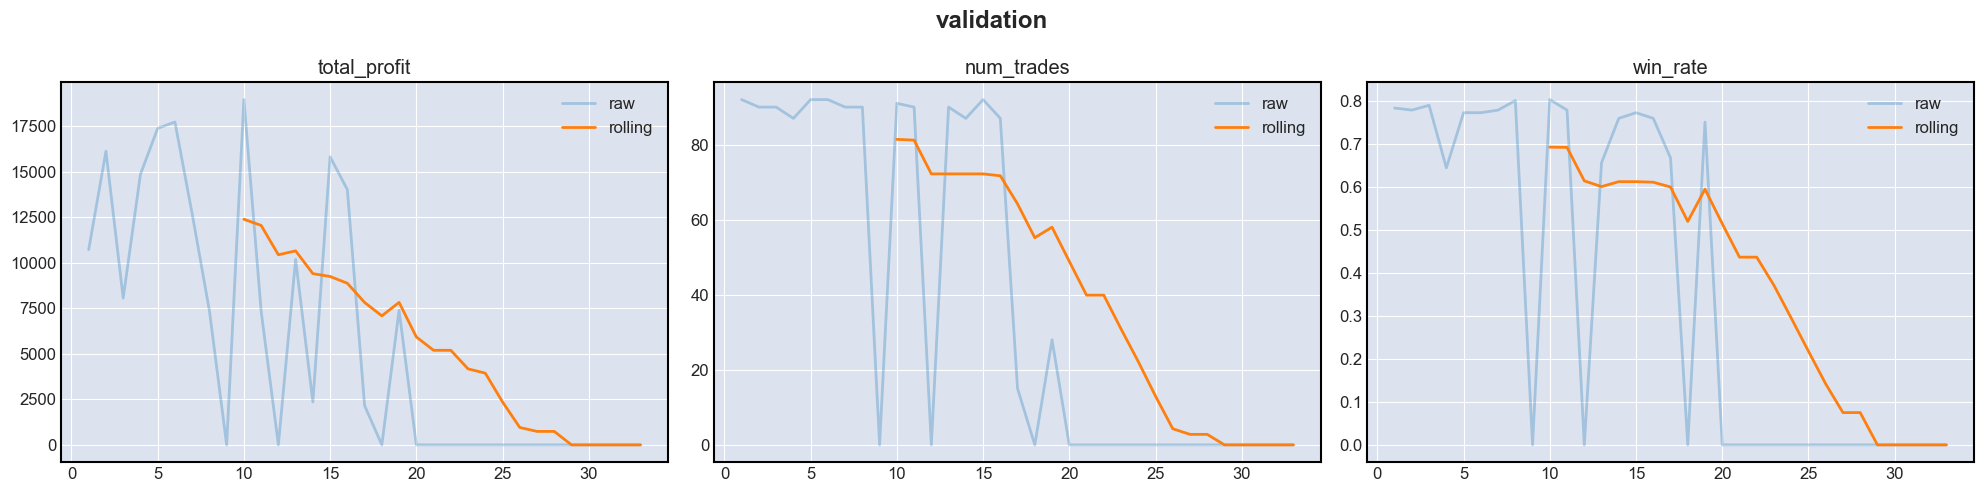

In [16]:
cols = [
    ('total_profit', 'rolling_profit'),
    ('num_trades', 'rolling_trades'),
    ('win_rate', 'rolling_winrate'),
]

for item in [(metrics, 'train'), (val_metrics, 'validation')]:
    temp = item[0]
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    temp['rolling_profit'] = temp['total_profit'].rolling(10).mean()
    temp['rolling_trades'] = temp['num_trades'].rolling(10).mean()
    temp['rolling_winrate'] = temp['win_rate'].rolling(10).mean()

    for ax, (col, smooth) in zip(axes.flatten(), cols):
        ax.plot(temp['episode'], temp[col], alpha=0.3, label="raw")
        ax.plot(temp['episode'], temp[smooth], label="rolling", linewidth=2)
        ax.set_title(col)
        ax.grid(True)
        ax.legend()

    fig.suptitle(item[1])
    plt.tight_layout()
    plt.show()

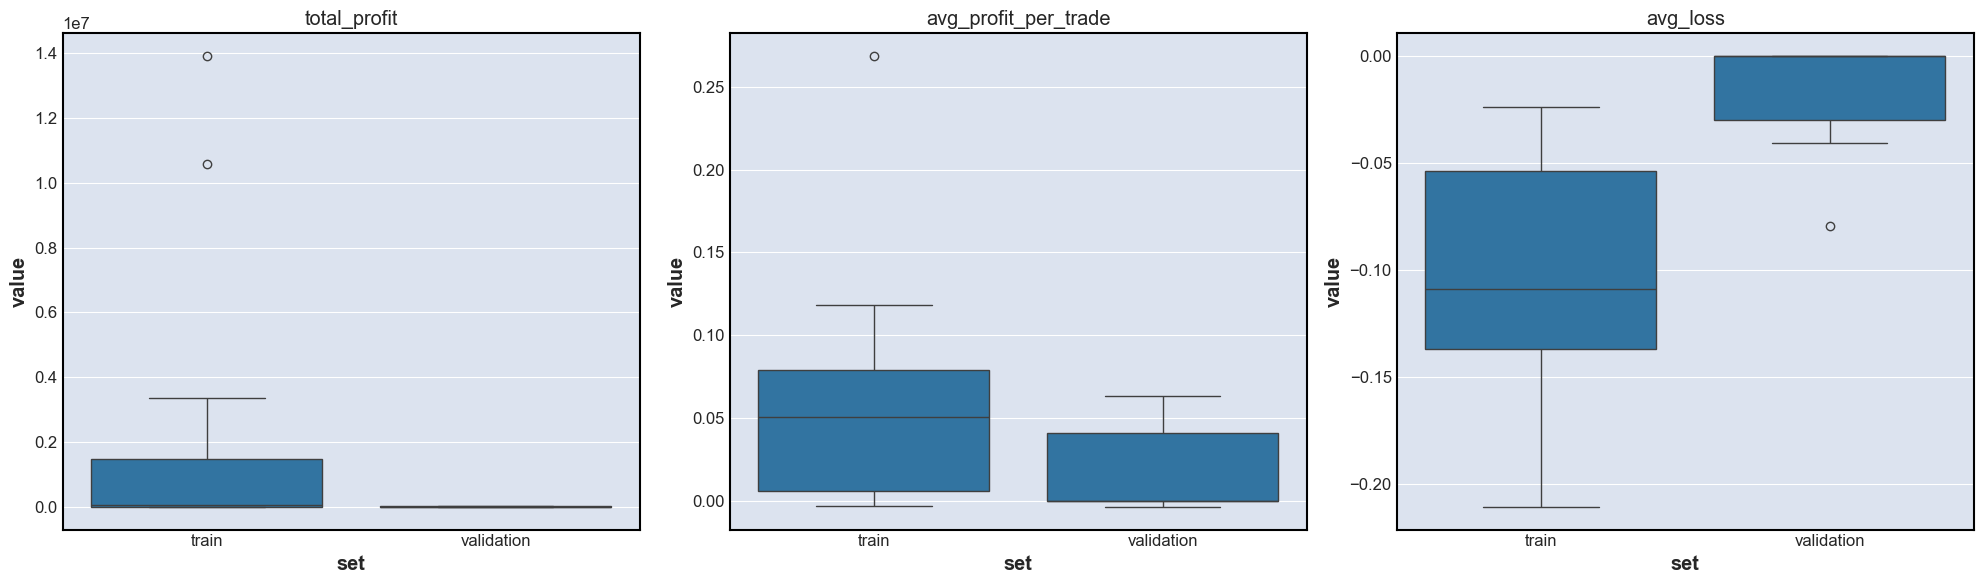

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
items = ['total_profit','avg_profit_per_trade', 'avg_loss']
for ax, item in zip(axs.flatten(), items):
    temp = pd.DataFrame({
        'value': np.concatenate([metrics[item], val_metrics[item]]),
        'set':   ['train'] * len(metrics[item]) + ['validation'] * len(val_metrics[item])
    })
    
    sns.boxplot(data=temp, x='set', y='value', ax=ax)
    ax.set_title(item)

plt.tight_layout()
plt.show()

In [18]:
# Funciones auxiliares
def stocks_price_format(n):
    if n < 0:
        return f"-${abs(n):.2f}"
    return f"${n:.2f}"

def plot_transactions(close_prices, transactions, title):
    prices = close_prices[-180:]

    # Use only last 180 transactions
    last_tx = transactions[-180:]

    # Compute offset so that the first selected price is x=0
    price_offset = len(close_prices) - 180

    # Shift transactions so they align with prices
    aligned_tx = [(t - price_offset, action, price) for t, action, price in last_tx]

    buy_x = [t for t, action, price in aligned_tx if action == 1]
    buy_y = [price for t, action, price in aligned_tx if action == 1]

    sell_x = [t for t, action, price in aligned_tx if action == 2]
    sell_y = [price for t, action, price in aligned_tx if action == 2]

    plt.figure(figsize=(14,6))
    plt.plot(prices, label="Price", linewidth=1)

    # Plot buys in green
    plt.scatter(buy_x, buy_y, marker="^", color="green", s=15, label="Buy")

    # Plot sells in red
    plt.scatter(sell_x, sell_y, marker="v", color="red", s=15, label="Sell")

    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

Predicciones del set de train durante la época que obtuvo mejor sharpe en validación. (Gráficado únicamente los últimos 180 días para facilitar la visualización)

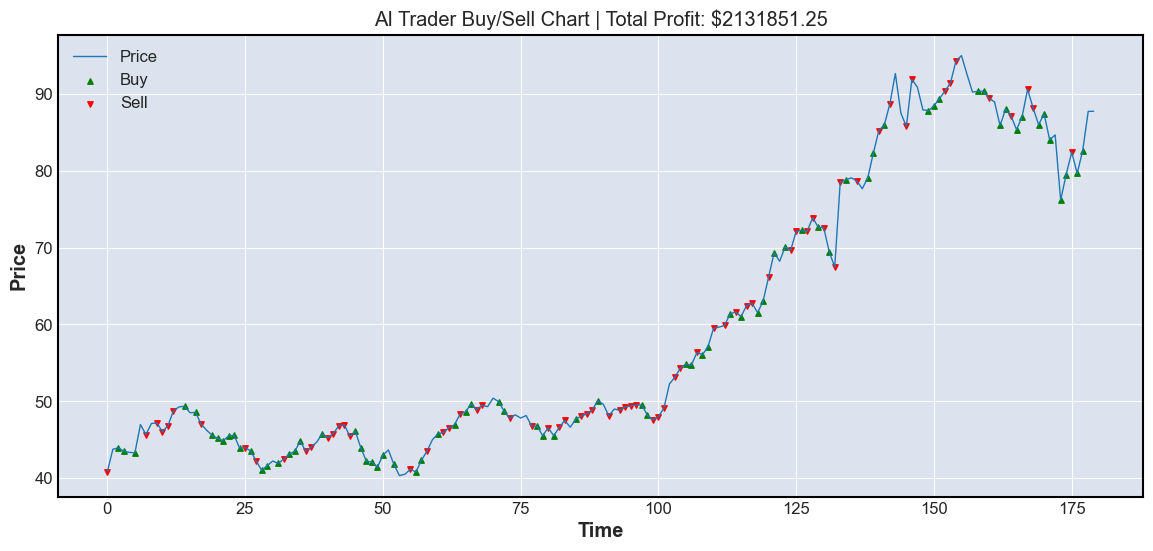

In [19]:
last_transactions = trader.transactions[best_episode -1]
best = metrics[metrics['episode'] == best_episode]
plot_transactions(train_prices, last_transactions, f"AI Trader Buy/Sell Chart | Total Profit: {stocks_price_format(best['total_profit'].iloc[0])}")

Parte 4 | Evalúa el modelo

In [20]:
# Recuperar el modelo con mejor rendimiento / o simplemente reestablecer los pesos (se hace abajo)
best_model = load_model(f"ai_trader_{best_episode}.keras", compile=False)

Visualización de las predicciones en el set de test

{'episode': 0, 'total_profit': 11267.65841674805, 'num_trades': 91, 'win_rate': 0.7032967032967034, 'avg_profit_per_trade': 0.03599488544508275, 'epsilon': 0.0, 'avg_loss': -0.021696007032087034, 'sharpe': 0.4677925333934767}


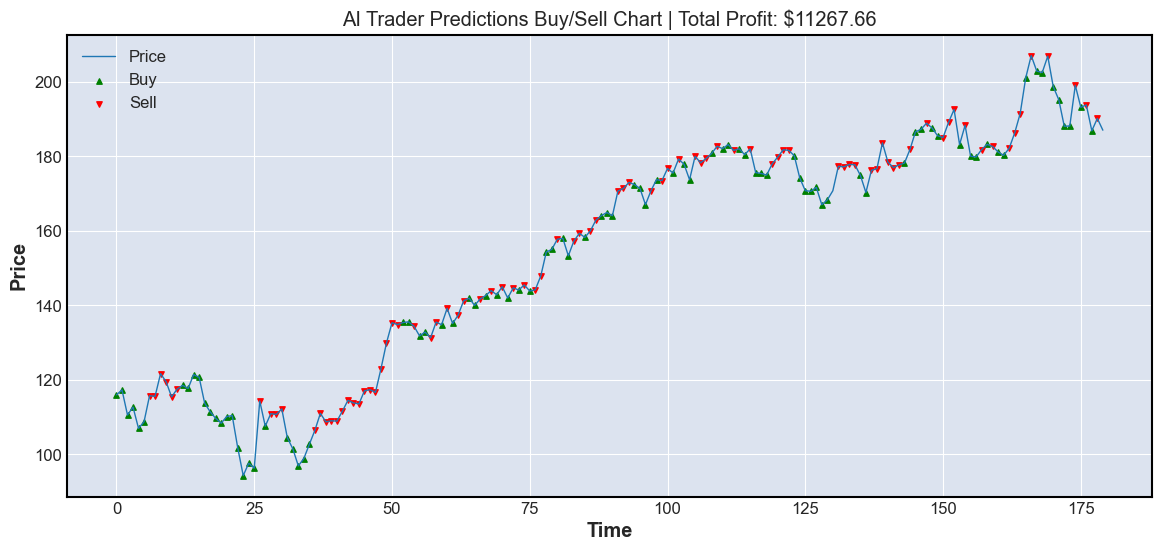

In [ ]:
# Reestablecer los pesos a los del mejor episodio
trader.model.set_weights(best_weights)
# Vaciar los datos anteriores
trader.reset_for_episode()
# Evaluación
test_results, transactions = evaluate_model(0, trader, test_features, test_prices)

print(test_results)
plot_transactions(test_prices, transactions, f"AI Trader Predictions Buy/Sell Chart | Total Profit: {stocks_price_format(test_results['total_profit'])}")

Porcentaje de retorno por cada trade individual en test

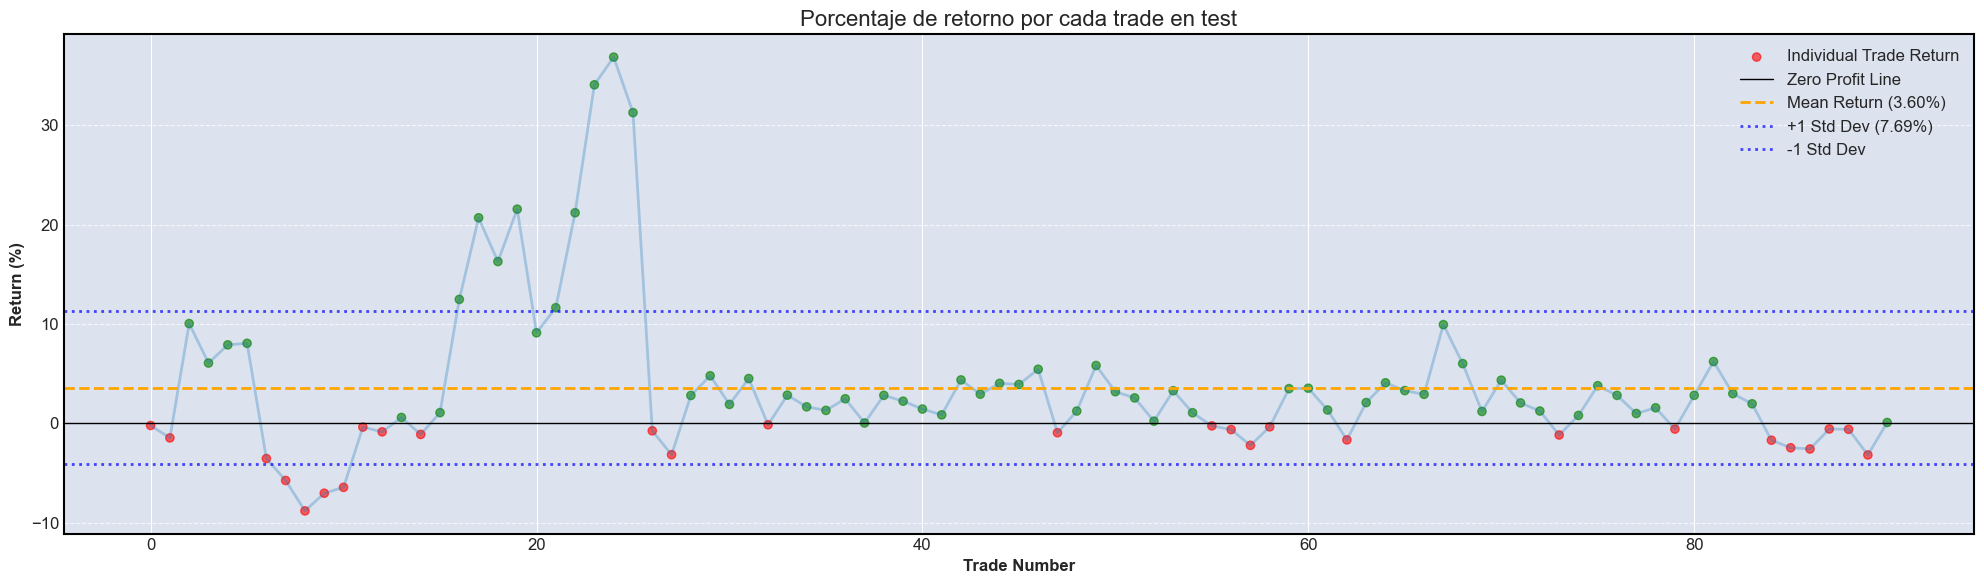

In [43]:
# Obtener el array de los útimos trades (en test) y cálculo de estadísticas
trades = np.array(trader.trades)
returns_percent = trades * 100
mean_return = np.mean(returns_percent)
std_dev = np.std(returns_percent)

plt.figure(figsize=(20, 6))

# Plot de cada trade según ganancia o pérdida
plt.scatter(range(len(returns_percent)), returns_percent, 
            c=np.where(returns_percent > 0, 'g', 'r'), # Verde para ganancias, rojo para pérididas
            alpha=0.6, 
            label='Individual Trade Return')

# Línia que une los trades para facilitar visualización
plt.plot(returns_percent, alpha=0.3)

# Líneas de contexto
# Zero Line 
plt.axhline(0, color='black', linestyle='-', linewidth=1, label='Zero Profit Line')

# Media
plt.axhline(mean_return, color='orange', linestyle='--', linewidth=2, label=f'Mean Return ({mean_return:.2f}%)')

# Desviación estándar
plt.axhline(mean_return + std_dev, color='blue', linestyle=':', alpha=0.7, label=f'+1 Std Dev ({std_dev:.2f}%)')
plt.axhline(mean_return - std_dev, color='blue', linestyle=':', alpha=0.7, label=f'-1 Std Dev')


plt.title('Porcentaje de retorno por cada trade en test', fontsize=16)
plt.xlabel('Trade Number', fontsize=12)
plt.ylabel('Return (%)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()